In [2]:
print ("hello world")

hello world


In [3]:
%pip install pandas scikit-learn xgboost

Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install lasio

Note: you may need to restart the kernel to use updated packages.


In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import xgboost as xgb
import lasio

In [6]:
# 1. Load Data
# Save the provided text block as a .las file, e.g., 'ATAGA_10.las'
las = lasio.read('ATAGA_10')
df = las.df() # Converts the LAS file directly into a Pandas DataFrame using DEPT as the index

In [7]:
df = df.dropna(subset=['GR', 'RHOB', 'NPHI', 'ILD', 'DT'])

# Define features (the 4 other logs) and target (Sonic)
X = df[['GR', 'RHOB', 'NPHI', 'ILD']]
y = df['DT']

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Train Model (XGBoost Regressor)
xgb_model = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=3)
xgb_model.fit(X_train, y_train)

# 4. Evaluate
y_pred_xgb = xgb_model.predict(X_test)
rmse = mean_squared_error(y_test, y_pred_xgb) ** 0.5

In [8]:
print(f"Target: DT (Sonic Log)")
print(f"XGBoost R2: {r2_score(y_test, y_pred_xgb):.3f}")
print(f"XGBoost RMSE: {rmse:.3f}")

Target: DT (Sonic Log)
XGBoost R2: 0.872
XGBoost RMSE: 2.239


In [9]:

%pip install shap

Note: you may need to restart the kernel to use updated packages.


In [10]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


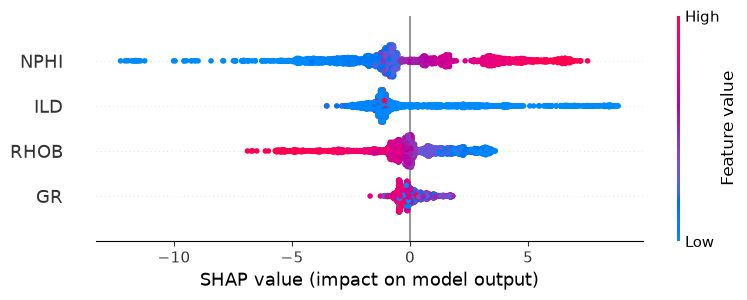

In [13]:
import shap
explainer = shap.Explainer(xgb_model)
shap_values = explainer(X_train)
shap.summary_plot(shap_values, X_train)



Target: DT (Sonic Log)
Random Forest R2: 0.881
Random Forest RMSE: 2.155


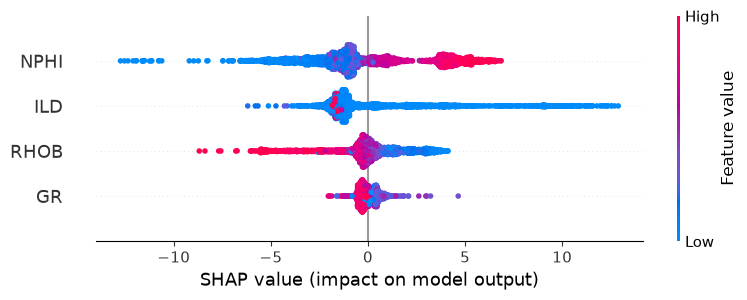

In [14]:
from sklearn.ensemble import RandomForestRegressor
import shap

# 3. Train Model (Random Forest Regressor)
# n_estimators = number of trees in the forest
# random_state ensures you get the exact same results every time you run it
rf_model = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
rf_model.fit(X_train, y_train)

# 4. Evaluate
y_pred_rf = rf_model.predict(X_test)
rmse_rf = mean_squared_error(y_test, y_pred_rf) ** 0.5

print(f"Target: DT (Sonic Log)")
print(f"Random Forest R2: {r2_score(y_test, y_pred_rf):.3f}")
print(f"Random Forest RMSE: {rmse_rf:.3f}")

# 5. Explainability (SHAP)
# TreeExplainer is specifically optimized for Random Forest and XGBoost
explainer = shap.TreeExplainer(rf_model) 
shap_values = explainer(X_train)
shap.summary_plot(shap_values, X_train)

In [16]:
# 1. Load the new well data
las_new = lasio.read('ATAGA_11')
df_new = las_new.df()

# 2. Clean the data (Drop NaNs in the exact same columns)
df_new = df_new.dropna(subset=['GR', 'RHOB', 'NPHI', 'ILD', 'DT'])

# 3. Separate features and target
# MUST be in the exact same order as your training data: GR, RHOB, NPHI, ILD
X_new = df_new[['GR', 'RHOB', 'NPHI', 'ILD']]
y_true = df_new['DT']

# 4. Generate predictions using your already-trained model (e.g., rf_model)
y_pred_new = rf_model.predict(X_new)

# 5. Evaluate the results
mse_new = mean_squared_error(y_true, y_pred_new)
rmse_new = mse_new ** 0.5
r2_new = r2_score(y_true, y_pred_new)

print("--- ATAGA 11 Blind Test Results ---")
print(f"R2 Score: {r2_new:.3f}")
print(f"MSE:      {mse_new:.3f}")
print(f"RMSE:     {rmse_new:.3f}")

--- ATAGA 11 Blind Test Results ---
R2 Score: 0.040
MSE:      72.266
RMSE:     8.501


--- Multi-Well Model Results ---
Combined R2 Score: 0.804
Combined RMSE:     3.945
--- ATAGA 5 Blind Test Results ---
R2 Score: -96.312
MSE:      123.706
RMSE:     11.122


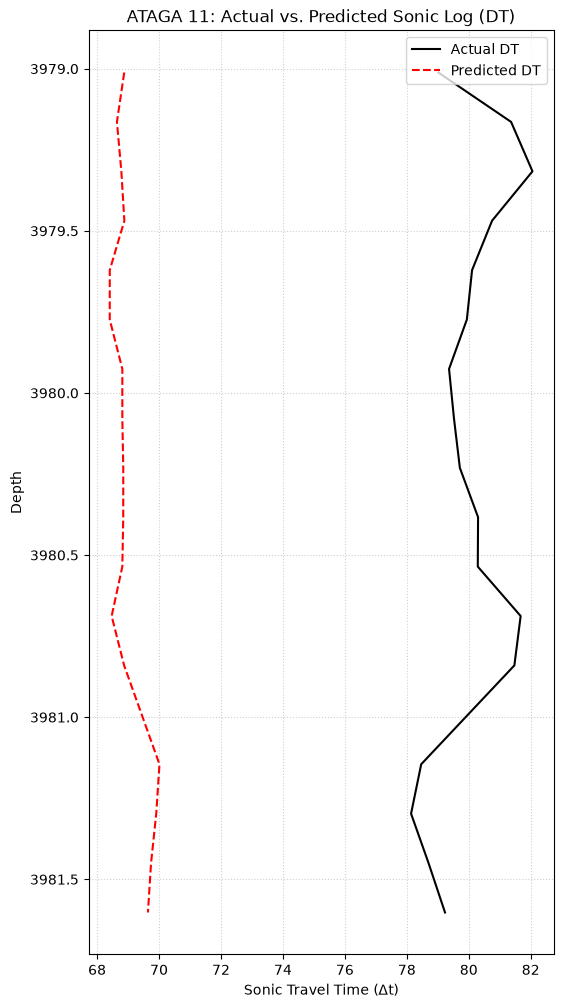

In [30]:
import lasio
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

# 1. Load and tag both wells
las_10 = lasio.read('ATAGA_10')
df_10 = las_10.df().reset_index() # Moves Depth from the index into a standard column
df_10['WELL'] = 'ATAGA_10'        # Tag the data so you know where it came from

las_11 = lasio.read('ATAGA_11')
df_11 = las_11.df().reset_index()
df_11['WELL'] = 'ATAGA_11'

# 2. Merge them into one massive dataset
df_combined = pd.concat([df_10, df_11], ignore_index=True)

# 3. Clean the combined data
# Convert fake LAS null values to real pandas NaNs, then drop the missing rows
df_combined.replace([-999.25, -9999.0, -999.0], pd.NA, inplace=True)
df_combined = df_combined.dropna(subset=['GR', 'RHOB', 'NPHI', 'ILD', 'DT'])

# 4. Define features and target
X = df_combined[['GR', 'RHOB', 'NPHI', 'ILD']]
y = df_combined['DT']

# 5. Split the data
# Because the data is randomly shuffled here, the model trains on pieces of BOTH wells
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 6. Train the Field-Wide Model
rf_model = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
rf_model.fit(X_train, y_train)

# 7. Evaluate
y_pred = rf_model.predict(X_test)
rmse = mean_squared_error(y_test, y_pred) ** 0.5

print("--- Multi-Well Model Results ---")
print(f"Combined R2 Score: {r2_score(y_test, y_pred):.3f}")
print(f"Combined RMSE:     {rmse:.3f}")

# 1. Load the new well data
las_new = lasio.read('ATAGA_5')
df_new = las_new.df()

# 2. Clean the data (CRITICAL FIX: Add the replace step here too)
df_new.replace([-999.25, -9999.0, -999.0], pd.NA, inplace=True)
df_new = df_new.dropna(subset=['GR', 'RHOB', 'NPHI', 'ILD', 'DT'])

# 3. Separate features and target
X_new = df_new[['GR', 'RHOB', 'NPHI', 'ILD']]
y_true = df_new['DT']

# 4. Generate predictions using your already-trained model
y_pred_new = rf_model.predict(X_new)

# 5. Evaluate the results
mse_new = mean_squared_error(y_true, y_pred_new)
rmse_new = mse_new ** 0.5
r2_new = r2_score(y_true, y_pred_new)

print("--- ATAGA 5 Blind Test Results ---")
print(f"R2 Score: {r2_new:.3f}")
print(f"MSE:      {mse_new:.3f}")
print(f"RMSE:     {rmse_new:.3f}")
import matplotlib.pyplot as plt

# Set up the figure size (tall and narrow is best for well logs)
plt.figure(figsize=(6, 12))

# Plot Actual DT (solid black line)
# Note: las.df() automatically sets Depth as the index, so we use df_new.index for the Y-axis
plt.plot(y_true.values, df_new.index, label='Actual DT', color='black', linewidth=1.5)

# Plot Predicted DT (dashed red line)
plt.plot(y_pred_new, df_new.index, label='Predicted DT', color='red', linewidth=1.5, linestyle='--')

# Invert the Y-axis so depth increases downwards
plt.gca().invert_yaxis()

# Add labels, grid, and formatting
plt.title('ATAGA 11: Actual vs. Predicted Sonic Log (DT)')
plt.ylabel('Depth')
plt.xlabel('Sonic Travel Time (Δt)')
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)

# Display the plot
plt.show()